In [1]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
from statsmodels.nonparametric.smoothers_lowess import lowess
import html
import matplotlib.pyplot as plt

Run a spearman correlation analysis and BH correction on the p values to find the most correlated pathways with age

In [2]:
qc1_pathabundance = pd.read_csv("qc1_pathabundance_cpm_n_reads_ge_2_mil.tsv", sep="\t", index_col=0)
# Show the shape as a check
print("qc1 pathabundance shape:", qc1_pathabundance.shape)

qc1 pathabundance shape: (695, 10193)


In [3]:
# Apply a filter to remove pathways that aren't in at least
# 10% of samples

names_of_kept_pathways = []

# Loop over the columns and filter out the stratified, age and weight columns
for col in qc1_pathabundance.columns:
    if "|" not in col and col not in ["age", "weight"]: 
        names_of_kept_pathways.append(col)

# Create a new dataframe with only the kept pathways
qc1_pathabundance_unstratified = qc1_pathabundance[names_of_kept_pathways]
# Double check the shape of the new dataframe
print("qc1 pathabundance unstratified shape:", qc1_pathabundance_unstratified.shape)

# Check which pathways have a non-zero abundance in each sample (per dog and per pathway)
is_pathway_present_in_dog = qc1_pathabundance_unstratified > 0
# Count the number of dogs in which each pathway is present
n_dogs_per_pathway = is_pathway_present_in_dog.sum()

# Calculate the proportion of dogs in which each pathway is present per pathway
proportion_of_dogs_per_pathway = n_dogs_per_pathway / qc1_pathabundance_unstratified.shape[0] # Shape[0] is number of rows or first entry

# Apply the 10% filter to keep only pathways that are present in at least 10% of dogs
is_passed_prevalence_filter = proportion_of_dogs_per_pathway >= 0.1

# Create a new dataframe with only the pathways that passed the prevalence filter
qc2_pathabundance_unstratified_10pct_prevalence = qc1_pathabundance_unstratified.loc[:, is_passed_prevalence_filter]
# .loc use label based selectors to select columns + all rows
print("qc2 pathabundance unstratified 10% prevalence shape:", qc2_pathabundance_unstratified_10pct_prevalence.shape)


qc1 pathabundance unstratified shape: (695, 458)
qc2 pathabundance unstratified 10% prevalence shape: (695, 309)


Spearman correlation for each pathway (vs age)

In [4]:
dog_ages = qc1_pathabundance["age"]

pathway_names = []
spearman_rho = []
spearman_pval = []

for pathway in qc2_pathabundance_unstratified_10pct_prevalence.columns:
    pathway_names.append(pathway)
    rho, p = spearmanr(qc2_pathabundance_unstratified_10pct_prevalence[pathway], dog_ages)
    spearman_rho.append(rho)
    spearman_pval.append(p)

# Check the length of the spearman correlations list
print("Number of spearman correlations calculated:", len(spearman_rho))

Number of spearman correlations calculated: 309


In [5]:
# Store pathway, rho and p in a new dataframe

spearman_correlation_df = pd.DataFrame({ # dataframe a dictionary of lists for pathway, rho and pval
    "pathway": pathway_names, # Column name: list of values
    "spearman_rho": spearman_rho,
    "p_value": spearman_pval
})

# Show the first 5 rows of the dataframe
# print("head of spearman correlation dataframe:")
# print(spearman_correlation_df.head()) 


In [6]:
# BH correct the p values
BH_correction_results = multipletests(spearman_correlation_df["p_value"],
              alpha=0.05, # significance level
              method="fdr_bh") # Benjamini-Hochberg method
q_values = BH_correction_results[1] # The second element of the result is the array of q-values

# Add the q-values to the dataframe
spearman_correlation_df["q_value"] = q_values

# print("Head of spearman correlation dataframe with q-values:")
# print(spearman_correlation_df.head())

# Sort the dataframe by q-value and p-value
spearman_correlation_df_sorted = spearman_correlation_df.sort_values(by=["q_value", "p_value"], 
                                                                     ascending=[True, True]) # Sort by the first, use the second to break ties
# Ascending order for both q-value and p-value, so the smallest values are at the top

# print("Head of sorted spearman correlation dataframe:")
# print(spearman_correlation_df_sorted.head())

In [7]:
# Check which q_values are less than 0.05
is_sig_correlation_with_age = spearman_correlation_df_sorted["q_value"] < 0.05

# Apply the filter to the sorted dataframe to get only the significant correlations
sig_pathways_spearman_df = spearman_correlation_df_sorted.loc[is_sig_correlation_with_age, :]

# Print shape of significant pathways dataframe
print("Shape of sig_pathways_spearman_df:", sig_pathways_spearman_df.shape)

Shape of sig_pathways_spearman_df: (257, 4)


In [8]:
# Save the spearman correlation data as a csv
sig_pathways_spearman_df.to_csv("table1_pathway_abundance_age_spearman_q_less_0.05.csv", index=False)
spearman_correlation_df_sorted.to_csv("supplementary_table_pathway_abundance_age_spearman_all.csv", index=False)

Make a barchart for rhos of the significant pathways
- sig_pathways_spearman_df = table1_pathway....

In [ ]:
# Pull out the top 5 positive correlations with age
sig_pathways_sorted_spearman_df = sig_pathways_spearman_df.sort_values(by="spearman_rho", ascending=False)
top_5_positive_correlations = sig_pathways_sorted_spearman_df.head(5)
print("Top 5 positive correlations with age:", top_5_positive_correlations)

# Pull out the top 5 negative correlations with age
top_5_negative_correlations = sig_pathways_sorted_spearman_df.tail(5)
print("Top 5 negative correlations with age:", top_5_negative_correlations)

# Print the full pathway names for the top 5 positive and negative correlations
# for pathway_name in top_5_positive_correlations["pathway"]:
    # print(pathway_name)
# for pathway_name in top_5_negative_correlations["pathway"]:
    # print(pathway_name)

Top 5 positive correlations with age:                                                pathway  spearman_rho  \
19   COLANSYN-PWY: colanic acid building blocks bio...      0.575081   
168  PWY-6467: Kdo transfer to lipid IVA III (Chlam...      0.558600   
291  PYRIDNUCSYN-PWY: NAD de novo biosynthesis I (f...      0.540728   
244                     PWY-7791: UMP biosynthesis III      0.537869   
23   DTDPRHAMSYN-PWY: dTDP-&beta;-L-rhamnose biosyn...      0.534925   

          p_value       q_value  
19   1.968252e-62  2.027300e-60  
168  2.817949e-58  1.451244e-56  
291  5.026719e-54  2.218937e-52  
244  2.279884e-53  8.806052e-52  
23   1.065217e-52  3.657244e-51  
Top 5 negative correlations with age:                                                pathway  spearman_rho  \
29                      FUCCAT-PWY: fucose degradation     -0.530480   
303  THRESYN-PWY: superpathway of L-threonine biosy...     -0.561395   
251             PWY-7977: L-methionine biosynthesis IV     -0.574571   

Classify pathways into MetaCyc superclass 1 and 2. Pathways are the unstratified ones with the 10% prevalence filter applied (309 pathways). Mapping was from file2meco package in R (MetaCyc_pathway_map), superclass 1 and 2, pathway name and id for each pathway.

Caution: 
1. Superclass 1 reappears in superclass 2 when there isn't a superclass 2 found
2. Superclass 2 can have multiple parent classes (joined together with && symbol)
3. Pathway_ids can have a -1 at the end, and as a result matching can be blocked

In [10]:
# Read in the metacyc pathway file
metacyc_pathway_map = pd.read_csv("metacyc_pathway_map.csv")
# Check col names so I know what to join on
print(metacyc_pathway_map.columns)

Index(['Superclass1', 'Superclass2', 'pathway', 'pathway_id'], dtype='str')


In [11]:
# Take table holding all the pathways I tested for correlation, that's what I am matching to the metacyc pathway map
spearman_correlation_df_sorted["pathway_id"] = spearman_correlation_df_sorted["pathway"].str.split(":", n=1).str[0] # n =1 to stop at the first colon
# only want the first item (pathway ID) to match to the metacyc pathway map, str[0] to get the first item of the split

# Check the pathway_id column
print(spearman_correlation_df_sorted["pathway_id"].head())

198        PWY-6936
232        PWY-7356
19     COLANSYN-PWY
251        PWY-7977
303     THRESYN-PWY
Name: pathway_id, dtype: object


In [12]:
# Join the tested pathways with the metacyc pathway map
table2_spearman_correlation_with_superclasses = spearman_correlation_df_sorted.merge(metacyc_pathway_map,
                                                                                     on="pathway_id", # Column to join on
                                                                                     how="left") # How controls the rows that are kept, 
# left means everything on the left table, regardless if it matches

# Check the matches
print(table2_spearman_correlation_with_superclasses.shape) # Check for 309 row count remaining
# Count number of rows with no Superclass1 (NaN value)
print("Number of rows without superclass1:", table2_spearman_correlation_with_superclasses["Superclass1"].isna().sum())
print("Column names:", table2_spearman_correlation_with_superclasses.columns)

(309, 8)
Number of rows without superclass1: 0
Column names: Index(['pathway_x', 'spearman_rho', 'p_value', 'q_value', 'pathway_id',
       'Superclass1', 'Superclass2', 'pathway_y'],
      dtype='str')


In [13]:
# Check if pathway_y includes the & and need to be cleaned
print("How many pathway_y ids includes the &:", table2_spearman_correlation_with_superclasses["pathway_y"].str.contains("&").sum())

# Merged everything, need to clean up the pathway name columns to remove the &, and rename pathway_x and pathway_y

How many pathway_y ids includes the &: 9


In [14]:
# Rename columns (pathway x and y) and clean up the pathway names
table2_spearman_correlation_with_superclasses = table2_spearman_correlation_with_superclasses.rename(columns={"pathway_x":"pathway_humann", 
                                                                                                              "pathway_y":"pathway_metacyc"})
# Check if rename went through correctly
print(table2_spearman_correlation_with_superclasses.columns)

# Replace the &greek letter with the actual greek letter by applying html.unescape function
table2_spearman_correlation_with_superclasses["pathway_metacyc"] = table2_spearman_correlation_with_superclasses["pathway_metacyc"].apply(html.unescape)
table2_spearman_correlation_with_superclasses["pathway_humann"] = table2_spearman_correlation_with_superclasses["pathway_humann"].apply(html.unescape)

# Count the rows containing the & again as a check
print("How many pathway_metacyc names includes the &:", table2_spearman_correlation_with_superclasses["pathway_metacyc"].str.contains("&").sum())
print("How many pathway_humann names includes the &:", table2_spearman_correlation_with_superclasses["pathway_humann"].str.contains("&").sum())


Index(['pathway_humann', 'spearman_rho', 'p_value', 'q_value', 'pathway_id',
       'Superclass1', 'Superclass2', 'pathway_metacyc'],
      dtype='str')
How many pathway_metacyc names includes the &: 0
How many pathway_humann names includes the &: 0


In [15]:
# Save as a csv
table2_spearman_correlation_with_superclasses.to_csv("table2_spearman_correlation_with_superclasses.csv", index=False)


In [16]:
# Some pathways have multiple classes, so split the pathway name into a row per class with their corresponding pathway
# Split on the &&
table2_spearman_correlation_with_superclasses["Superclass2_split"] = table2_spearman_correlation_with_superclasses["Superclass2"].str.split("&&")

# Make the class names into seperate rows (one row per class)
table2_row_per_class = table2_spearman_correlation_with_superclasses.explode("Superclass2_split")

# Check row number
print("Number of rows after seperating classes:", table2_row_per_class.shape[0])

Number of rows after seperating classes: 340


In [17]:
# Count how many pathways there are in each class

# Value counts counts how many rows have each unique value in the column
pathways_per_class_post_split = table2_row_per_class["Superclass2_split"].value_counts()
print(pathways_per_class_post_split)

Superclass2_split
Cofactor, Carrier, and Vitamin Biosynthesis          52
Amino Acid Biosynthesis                              42
Nucleoside and Nucleotide Biosynthesis               30
Fermentation                                         22
Carbohydrate Degradation                             20
Fatty Acid and Lipid Biosynthesis                    19
Carbohydrate Biosynthesis                            16
Nucleoside and Nucleotide Degradation                12
Cell Structure Biosynthesis                          11
Carboxylic Acid Degradation                           8
Amino Acid Degradation                                7
Tetrapyrrole Biosynthesis                             7
Inorganic Nutrient Metabolism                         7
Secondary Metabolite Biosynthesis                     6
TCA cycle                                             6
Amide, Amidine, Amine, and Polyamine Biosynthesis     6
C1 Compound Utilization and Assimilation              5
Fatty Acid and Lipid Degradati

Now I'm cleaning up and prepping the data to do analysis of abundance vs age using superclasses

In [18]:
# Reshape the data long form data

# Make sample_ids regular column instead of an index
qc2_pathabundance_unstratified_10pct_prevalence_index_reset = qc2_pathabundance_unstratified_10pct_prevalence.reset_index(names="sample_id") # Rename column as sample_id

# Make columns into rows (long form)
qc2_pathabundance_unstratified_10pct_prevalence_cpm_long = qc2_pathabundance_unstratified_10pct_prevalence_index_reset.melt(
                                                                id_vars="sample_id", # Column to keep as an identifier
                                                                var_name="pathway_humann", # Name column to store the old column headers
                                                                value_name="cpm" # Column that holds the numbers for each dog (abundance data)

)

# Print row count since reshaping expanded the rows
print("Row count post reshaping to long form:", qc2_pathabundance_unstratified_10pct_prevalence_cpm_long.shape[0])

Row count post reshaping to long form: 214755


/var/folders/5b/l784xc0s3y50n29bphbkyb8w0000gn/T/ipykernel_56002/2126159438.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  qc2_pathabundance_unstratified_10pct_prevalence_index_reset = qc2_pathabundance_unstratified_10pct_prevalence.reset_index(names="sample_id") # Rename column as sample_id


In [19]:
# Split the pathway names to get the pathway_id so the superclasses data have something to match on

# Same as splitting the spearman correlation data
qc2_pathabundance_unstratified_10pct_prevalence_cpm_long["pathway_id"] = qc2_pathabundance_unstratified_10pct_prevalence_cpm_long["pathway_humann"].str.split(":", n=1).str[0] # n =1 to stop at the first colon
# only want the first item (pathway ID) to match to the metacyc pathway map, str[0] to get the first item of the split

# Replace the &greek letter with the actual greek letter by applying html.unescape function; exactly how it was done with the spearman_df
qc2_pathabundance_unstratified_10pct_prevalence_cpm_long["pathway_humann"] = qc2_pathabundance_unstratified_10pct_prevalence_cpm_long["pathway_humann"].apply(html.unescape)

# Count how many rows still have the & (should be 0)
print("How many pathway_humann names includes the &:", qc2_pathabundance_unstratified_10pct_prevalence_cpm_long["pathway_humann"].str.contains("&").sum())


How many pathway_humann names includes the &: 0


In [20]:
# Merge the pathway's superclasses to each row (dog-pathway pair)

# Select only necessary columns from the superclass table and merge
qc2_pathabundance_unstratified_10pct_prevalence_superclasses = qc2_pathabundance_unstratified_10pct_prevalence_cpm_long.merge(table2_row_per_class[["pathway_id", "Superclass1", "Superclass2_split"]],
                                                               on="pathway_id",
                                                               how="left"

) # Merge called on the table with the rows you want to keep

# How many rows are there in the final version
print("Row count of the merged table with superclasses:", qc2_pathabundance_unstratified_10pct_prevalence_superclasses.shape[0])

# This is the data that all the rest of the analysis is build on

Row count of the merged table with superclasses: 236300


Amino acid synthesis and degradation vs age figure

One dot is a dog in one class so every dog is shown twice (because we have two categories of classes). Mean CPM across all the pathways in the specific class (y axis) compared to dog age (x-axis). The two superclasses are in superclass2 and are amino acid biosynthesis and degradation.
The lines are LOESS

In [21]:
# Mean CPM (abundance) per dog in per class
qc2_pathabundance_unstratified_10pct_prevalence_grouped_superclasses = qc2_pathabundance_unstratified_10pct_prevalence_superclasses.groupby(["sample_id", "Superclass2_split"])["cpm"].mean().reset_index()
# Groupby() groups the values in a dataframe by the values in 1 or more columns
# Point to the cpm column for it to average
# Reset the index: results go back to a regular table

# Print the shape of the grouped superclasses df
print("Shape of the grouped superclass df:", qc2_pathabundance_unstratified_10pct_prevalence_grouped_superclasses.shape)


Shape of the grouped superclass df: (27800, 3)


In [ ]:
# Keep the two protein (amino acid class) data

amino_acid_classes = ["Amino Acid Biosynthesis", "Amino Acid Degradation"]

# T/F test: For each row of Superclass2_split is the class (.isin()) the amino_acid class list and keep only the true rows
is_amino_acid_class = qc2_pathabundance_unstratified_10pct_prevalence_grouped_superclasses["Superclass2_split"].isin(amino_acid_classes)

# Filtered df of amino acid mean cpm
amino_acid_mean_cpm_df = qc2_pathabundance_unstratified_10pct_prevalence_grouped_superclasses[is_amino_acid_class].copy()


# Print the number of rows
print("Number of rows - expect 695 dogs x 2 superclasses:", amino_acid_mean_cpm_df.shape[0])

# Map the dog ages from the dog_ages variable onto the dogs in the amino acid data by sample_id
# Write the matching ages to an age column in the amino acid data
amino_acid_mean_cpm_df["age"] = amino_acid_mean_cpm_df["sample_id"].map(dog_ages)

# Print the number of rows of dogs with no ages
print("Number of rows of dogs without an age: ", amino_acid_mean_cpm_df["age"].isna().sum())

Number of rows - expect 695 dogs x 2 superclasses: 1390
Number of rows of dogs without an age:  0


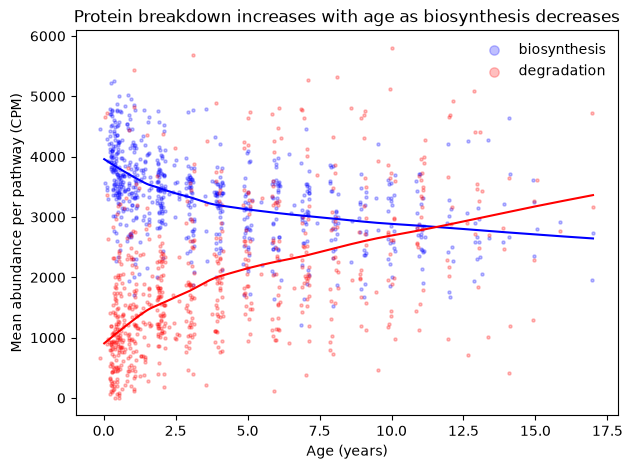

In [23]:
# Draw the plot

fig, ax = plt.subplots(figsize=(7,5))

# Indicate which rows are Amino Acid Biosynthesis
is_aa_biosynthesis = amino_acid_mean_cpm_df["Superclass2_split"] == "Amino Acid Biosynthesis"

# Indicate Amino Acid Degradation
is_aa_degradation = amino_acid_mean_cpm_df["Superclass2_split"] == "Amino Acid Degradation"

# Select biosynthesis and degradation rows from the df > make dfs with biosynthesis and degradation data
aa_biosynthesis_df = amino_acid_mean_cpm_df[is_aa_biosynthesis].copy()
aa_degradation_df = amino_acid_mean_cpm_df[is_aa_degradation].copy()

# Jitter the ages sideways since they overlap a lot
jitter_offsets = np.random.default_rng(42).uniform(-0.15, 0.15, len(aa_biosynthesis_df)) 
# .uniform(low bound, high bound, how many numbers (n_dogs) to generate), the bounds are for amount of offset
# 42 is the seed

# Add the offset to the ages
aa_biosynthesis_df["age_jittered"] = aa_biosynthesis_df["age"] + jitter_offsets
aa_degradation_df["age_jittered"] = aa_degradation_df["age"] + jitter_offsets



# Draw biosynthesis graph
ax.scatter(aa_biosynthesis_df["age_jittered"], aa_biosynthesis_df["cpm"], # X and Y axis of scatter
           alpha=0.25, # Transparency
           s=5, # Point size
           color="blue",
           label="biosynthesis") # Label for legend

# LOWESS : synthesis
biosynthesis_lowess = lowess(aa_biosynthesis_df["cpm"], aa_biosynthesis_df["age"], # Y and then x
       frac=0.5, # Smoothness
       return_sorted=True) # Sort by age/x axis

# Plot LOWESS: synthesis
biosynlowess_x_vals = biosynthesis_lowess[:,0]
biosynlowess_y_vals = biosynthesis_lowess[:,1]
ax.plot(
    biosynlowess_x_vals,
    biosynlowess_y_vals,
    color="blue",
    linewidth=1.5
)

# Draw degradation graph
ax.scatter(aa_degradation_df["age_jittered"], aa_degradation_df["cpm"], # X and Y axis of scatter
           alpha=0.25, # Transparency
           s=5, # Point size
           color="red",
           label="degradation") # Label for legend

# LOWESS : degradation
degradation_lowess = lowess(aa_degradation_df["cpm"], aa_degradation_df["age"], # Y and then x
       frac=0.5, # Smoothness
       return_sorted=True) # Sort by age/x axis

# Plot LOWESS: degradation
deglowess_x_vals = degradation_lowess[:,0]
deglowess_y_vals = degradation_lowess[:,1]
ax.plot(
    deglowess_x_vals,
    deglowess_y_vals,
    color="red",
    linewidth=1.5
)

# Axis titles and legend
ax.set_xlabel("Age (years)")
ax.set_ylabel("Mean abundance per pathway (CPM)")
ax.set_title("Protein breakdown increases with age as biosynthesis decreases")
ax.legend(
    frameon=False,
    loc="best",
    markerscale=3 # Make the legend dots more legible
)
fig.savefig("figure1_humann_aa_age.pdf", bbox_inches="tight")
fig.savefig("figure1_humann_aa_age.png", dpi=300, bbox_inches="tight")

Now do the same thing for carbohydrates, using the same mean abundance (cpm) per class per dog used in amino acid biosynthesis

Carbohydrate synthesis and degradation vs age figure

One dot is a dog in one class so every dog is shown twice (because we have two categories of classes). Mean CPM across all the pathways in the specific class (y axis) compared to dog age (x-axis). The two superclasses are in superclass2 and are carbohydrate biosynthesis and degradation.
The lines are LOESS. 

In [ ]:
# Keep the two carb classes

carb_classes = ["Carbohydrate Biosynthesis", "Carbohydrate Degradation"]

# T/F test: For each row of Superclass2_split is the class (.isin()) the carb class list and keep only the true rows
is_carb_class = qc2_pathabundance_unstratified_10pct_prevalence_grouped_superclasses["Superclass2_split"].isin(carb_classes)

# Filtered df of carb mean cpm
carb_mean_cpm_df = qc2_pathabundance_unstratified_10pct_prevalence_grouped_superclasses[is_carb_class].copy()


# Print the number of rows
print("Number of rows - expect 695 dogs x 2 superclasses:", carb_mean_cpm_df.shape[0])

# Map the dog ages from the dog_ages variable onto the dogs in the carb data by sample_id
# Write the matching ages to an age column in the carb data
carb_mean_cpm_df["age"] = carb_mean_cpm_df["sample_id"].map(dog_ages)

# Print the number of rows of dogs with no ages
print("Number of rows of dogs without an age: ", carb_mean_cpm_df["age"].isna().sum())

Number of rows - expect 695 dogs x 2 superclasses: 1390
Number of rows of dogs without an age:  0


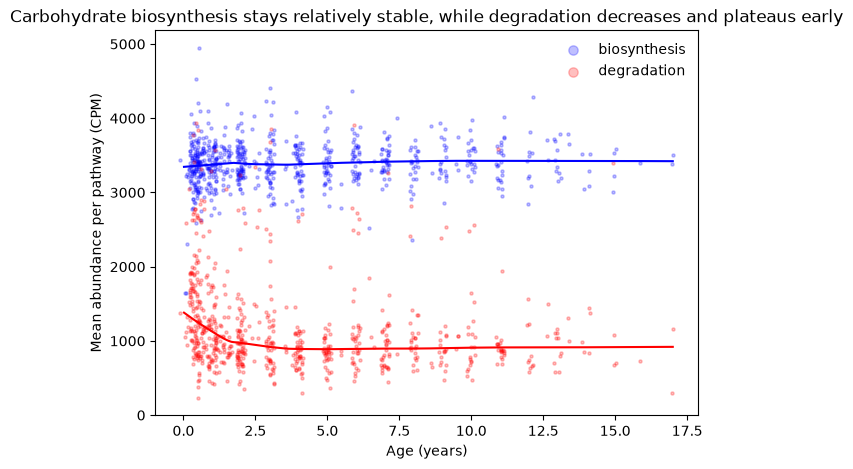

In [25]:
# Draw the plot

fig, ax = plt.subplots(figsize=(7,5))

# Indicate which rows are Carb Biosynthesis
is_carb_biosynthesis = carb_mean_cpm_df["Superclass2_split"] == "Carbohydrate Biosynthesis"

# Indicate Carb Degradation
is_carb_degradation = carb_mean_cpm_df["Superclass2_split"] == "Carbohydrate Degradation"

# Select biosynthesis and degradation rows from the df > make dfs with biosynthesis and degradation data
carb_biosynthesis_df = carb_mean_cpm_df[is_carb_biosynthesis].copy()
carb_degradation_df = carb_mean_cpm_df[is_carb_degradation].copy()

# Jitter the ages sideways since they overlap a lot
jitter_offsets_carb = np.random.default_rng(42).uniform(-0.15, 0.15, len(carb_biosynthesis_df)) 
# .uniform(low bound, high bound, how many numbers (n_dogs) to generate), the bounds are for amount of offset
# 42 is the seed

# Add the offset to the ages
carb_biosynthesis_df["age_jittered"] = carb_biosynthesis_df["age"] + jitter_offsets_carb
carb_degradation_df["age_jittered"] = carb_degradation_df["age"] + jitter_offsets_carb



# Draw biosynthesis graph
ax.scatter(carb_biosynthesis_df["age_jittered"], carb_biosynthesis_df["cpm"], # X and Y axis of scatter
           alpha=0.25, # Transparency
           s=5, # Point size
           color="blue",
           label="biosynthesis") # Label for legend

# LOWESS : synthesis
carb_biosynthesis_lowess = lowess(carb_biosynthesis_df["cpm"], carb_biosynthesis_df["age"], # Y and then x
       frac=0.5, # Smoothness
       return_sorted=True) # Sort by age/x axis

# Plot LOWESS: synthesis
carb_biosynlowess_x_vals = carb_biosynthesis_lowess[:,0]
carb_biosynlowess_y_vals = carb_biosynthesis_lowess[:,1]
ax.plot(
    carb_biosynlowess_x_vals,
    carb_biosynlowess_y_vals,
    color="blue",
    linewidth=1.5
)

# Draw degradation graph
ax.scatter(carb_degradation_df["age_jittered"], carb_degradation_df["cpm"], # X and Y axis of scatter
           alpha=0.25, # Transparency
           s=5, # Point size
           color="red",
           label="degradation") # Label for legend

# LOWESS : degradation
carb_degradation_lowess = lowess(carb_degradation_df["cpm"], carb_degradation_df["age"], # Y and then x
       frac=0.5, # Smoothness
       return_sorted=True) # Sort by age/x axis

# Plot LOWESS: degradation
carb_deglowess_x_vals = carb_degradation_lowess[:,0]
carb_deglowess_y_vals = carb_degradation_lowess[:,1]
ax.plot(
    carb_deglowess_x_vals,
    carb_deglowess_y_vals,
    color="red",
    linewidth=1.5
)

# Axis titles and legend
ax.set_xlabel("Age (years)")
ax.set_ylabel("Mean abundance per pathway (CPM)")
ax.set_title("Carbohydrate biosynthesis stays relatively stable, while degradation decreases and plateaus early")
ax.legend(
    frameon=False,
    loc="best",
    markerscale=3 # Make the legend dots more legible
)
fig.savefig("figure1_humann_carb_age.pdf", bbox_inches="tight")
fig.savefig("figure1_humann_carb_age.png", dpi=300, bbox_inches="tight")

Now do the same thing for lipids, using the same mean abundance (cpm) per class per dog used in amino acid biosynthesis

lipid synthesis and degradation vs age figure

One dot is a dog in one class so every dog is shown twice (because we have two categories of classes). Mean CPM across all the pathways in the specific class (y axis) compared to dog age (x-axis). The two superclasses are in superclass2 and are carbohydrate biosynthesis and degradation.
The lines are LOESS. 

In [ ]:
# Keep the two lipid classes

lipid_classes = ["Fatty Acid and Lipid Biosynthesis", "Fatty Acid and Lipid Degradation"]

# T/F test: For each row of Superclass2_split is the class (.isin()) the lipid class list and keep only the true rows
is_lipid_class = qc2_pathabundance_unstratified_10pct_prevalence_grouped_superclasses["Superclass2_split"].isin(lipid_classes)

# Filtered df of lipid mean cpm
lipid_mean_cpm_df = qc2_pathabundance_unstratified_10pct_prevalence_grouped_superclasses[is_lipid_class].copy()


# Print the number of rows
print("Number of rows - expect 695 dogs x 2 superclasses:", lipid_mean_cpm_df.shape[0])

# Map the dog ages from the dog_ages variable onto the dogs in the lipid data by sample_id
# Write the matching ages to an age column in the lipid data
lipid_mean_cpm_df["age"] = lipid_mean_cpm_df["sample_id"].map(dog_ages)

# Print the number of rows of dogs with no ages
print("Number of rows of dogs without an age: ", lipid_mean_cpm_df["age"].isna().sum())

Number of rows - expect 695 dogs x 2 superclasses: 1390
Number of rows of dogs without an age:  0


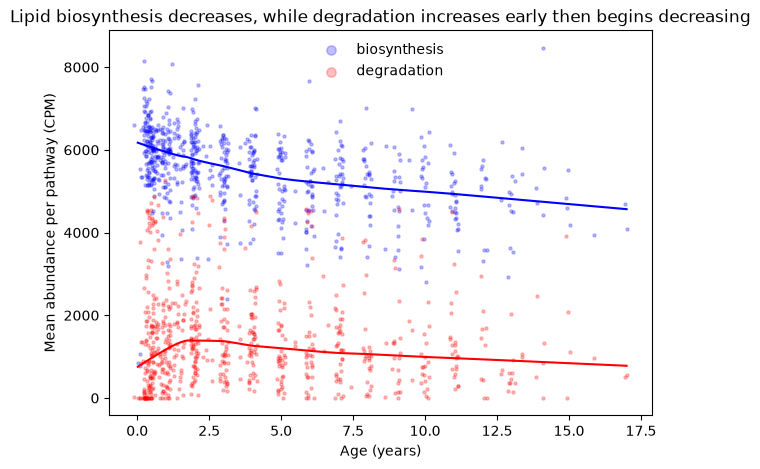

In [30]:
# Draw the plot

fig, ax = plt.subplots(figsize=(7,5))

# Indicate which rows are lipid Biosynthesis
is_lipid_biosynthesis = lipid_mean_cpm_df["Superclass2_split"] == "Fatty Acid and Lipid Biosynthesis"

# Indicate Lipid Degradation
is_lipid_degradation = lipid_mean_cpm_df["Superclass2_split"] == "Fatty Acid and Lipid Degradation"

# Select biosynthesis and degradation rows from the df > make dfs with biosynthesis and degradation data
lipid_biosynthesis_df = lipid_mean_cpm_df[is_lipid_biosynthesis].copy()
lipid_degradation_df = lipid_mean_cpm_df[is_lipid_degradation].copy()

# Jitter the ages sideways since they overlap a lot
jitter_offsets_lipid = np.random.default_rng(42).uniform(-0.15, 0.15, len(lipid_biosynthesis_df)) 
# .uniform(low bound, high bound, how many numbers (n_dogs) to generate), the bounds are for amount of offset
# 42 is the seed

# Add the offset to the ages
lipid_biosynthesis_df["age_jittered"] = lipid_biosynthesis_df["age"] + jitter_offsets_lipid
lipid_degradation_df["age_jittered"] = lipid_degradation_df["age"] + jitter_offsets_lipid



# Draw biosynthesis graph
ax.scatter(lipid_biosynthesis_df["age_jittered"], lipid_biosynthesis_df["cpm"], # X and Y axis of scatter
           alpha=0.25, # Transparency
           s=5, # Point size
           color="blue",
           label="biosynthesis") # Label for legend

# LOWESS : synthesis
lipid_biosynthesis_lowess = lowess(lipid_biosynthesis_df["cpm"], lipid_biosynthesis_df["age"], # Y and then x
       frac=0.5, # Smoothness
       return_sorted=True) # Sort by age/x axis

# Plot LOWESS: synthesis
lipid_biosynlowess_x_vals = lipid_biosynthesis_lowess[:,0]
lipid_biosynlowess_y_vals = lipid_biosynthesis_lowess[:,1]
ax.plot(
    lipid_biosynlowess_x_vals,
    lipid_biosynlowess_y_vals,
    color="blue",
    linewidth=1.5
)

# Draw degradation graph
ax.scatter(lipid_degradation_df["age_jittered"], lipid_degradation_df["cpm"], # X and Y axis of scatter
           alpha=0.25, # Transparency
           s=5, # Point size
           color="red",
           label="degradation") # Label for legend

# LOWESS : degradation
lipid_degradation_lowess = lowess(lipid_degradation_df["cpm"], lipid_degradation_df["age"], # Y and then x
       frac=0.5, # Smoothness
       return_sorted=True) # Sort by age/x axis

# Plot LOWESS: degradation
lipid_deglowess_x_vals = lipid_degradation_lowess[:,0]
lipid_deglowess_y_vals = lipid_degradation_lowess[:,1]
ax.plot(
    lipid_deglowess_x_vals,
    lipid_deglowess_y_vals,
    color="red",
    linewidth=1.5
)

# Axis titles and legend
ax.set_xlabel("Age (years)")
ax.set_ylabel("Mean abundance per pathway (CPM)")
ax.set_title("Lipid biosynthesis decreases, while degradation increases early then begins decreasing")
ax.legend(
    frameon=False,
    loc="best",
    markerscale=3 # Make the legend dots more legible
)
fig.savefig("figure1_humann_lipid_age.pdf", bbox_inches="tight")
fig.savefig("figure1_humann_lipid_age.png", dpi=300, bbox_inches="tight")